# 01 · First look at the data

**Question this project answers:** given a credit card customer's last six months of history,
how likely are they to **default** (fail to pay their bill) next month?

In finance this probability is called the **PD (Probability of Default)**. Banks use it to decide
who gets credit, how much, and at what interest rate.

This notebook only *looks* at the data: what each column means and whether anything looks odd.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from credit_risk.data import load_raw

pd.set_option("display.max_columns", 30)
df = load_raw()
print(f"{df.shape[0]:,} customers, {df.shape[1]} columns")
df.head()

30,000 customers, 24 columns


,credit_limit,sex,education,marriage,age,pay_status_sep,pay_status_aug,pay_status_jul,pay_status_jun,pay_status_may,pay_status_apr,bill_amt_sep,bill_amt_aug,bill_amt_jul,bill_amt_jun,bill_amt_may,bill_amt_apr,paid_amt_sep,paid_amt_aug,paid_amt_jul,paid_amt_jun,paid_amt_may,paid_amt_apr,default
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## What the columns mean

| Group | Columns | Meaning |
|---|---|---|
| Profile | `credit_limit`, `sex`, `education`, `marriage`, `age` | Who the customer is and how much credit the bank gave them |
| Repayment status | `pay_status_apr` … `pay_status_sep` | Each month: -1 = paid on time, 1 = one month late, 2 = two months late, … |
| Bills | `bill_amt_apr` … `bill_amt_sep` | How much the customer owed on each monthly statement |
| Payments | `paid_amt_apr` … `paid_amt_sep` | How much they actually paid that month |
| **Target** | `default` | **1 = defaulted in October 2005**, 0 = paid |

Money is in New Taiwan dollars (NT$).

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   credit_limit    30000 non-null  int64
 1   sex             30000 non-null  int64
 2   education       30000 non-null  int64
 3   marriage        30000 non-null  int64
 4   age             30000 non-null  int64
 5   pay_status_sep  30000 non-null  int64
 6   pay_status_aug  30000 non-null  int64
 7   pay_status_jul  30000 non-null  int64
 8   pay_status_jun  30000 non-null  int64
 9   pay_status_may  30000 non-null  int64
 10  pay_status_apr  30000 non-null  int64
 11  bill_amt_sep    30000 non-null  int64
 12  bill_amt_aug    30000 non-null  int64
 13  bill_amt_jul    30000 non-null  int64
 14  bill_amt_jun    30000 non-null  int64
 15  bill_amt_may    30000 non-null  int64
 16  bill_amt_apr    30000 non-null  int64
 17  paid_amt_sep    30000 non-null  int64
 18  paid_amt_aug    30000 non-null  int64

## How many customers defaulted?

This is the most important number in the dataset. If only a small share of customers default,
the data is **imbalanced**, and a lazy model that always says "won't default" would still look accurate.
We will deal with that in later milestones.

default
paid         23364
defaulted     6636
Name: count, dtype: int64

Default rate: 22.1%


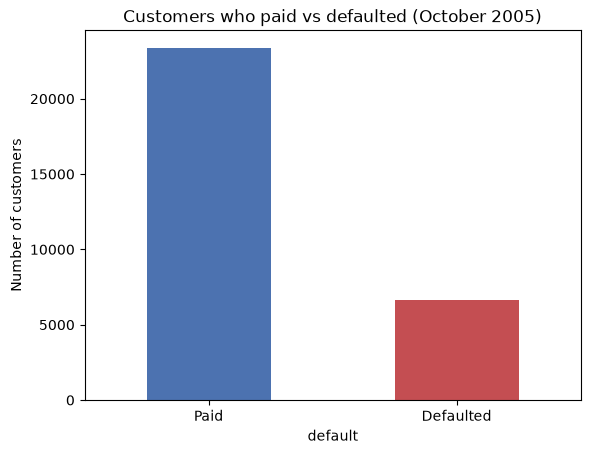

In [3]:
counts = df["default"].value_counts().sort_index()
print(counts.rename({0: "paid", 1: "defaulted"}))
print(f"\nDefault rate: {df['default'].mean():.1%}")

ax = counts.rename({0: "Paid", 1: "Defaulted"}).plot.bar(color=["#4C72B0", "#C44E52"], rot=0)
ax.set_title("Customers who paid vs defaulted (October 2005)")
ax.set_ylabel("Number of customers")
plt.show()

So about **22% defaulted** and 78% paid. A model that always predicts "paid" would be 78% accurate
while catching zero defaulters, which is why we won't judge models by accuracy.

## Basic statistics for the money columns

In [4]:
df[["credit_limit", "age", "bill_amt_sep", "paid_amt_sep"]].describe().round(0)

,credit_limit,age,bill_amt_sep,paid_amt_sep
count,30000.0,30000.0,30000.0,30000.0
mean,167484.0,35.0,51223.0,5664.0
std,129748.0,9.0,73636.0,16563.0
min,10000.0,21.0,-165580.0,0.0
25%,50000.0,28.0,3559.0,1000.0
50%,140000.0,34.0,22382.0,2100.0
75%,240000.0,41.0,67091.0,5006.0
max,1000000.0,79.0,964511.0,873552.0


Things to notice:
- Credit limits range from NT$10,000 to NT$1,000,000, and the median is NT$140,000.
- Some **bills are negative**. That means the customer overpaid and the bank owes *them* money.
  It's not an error, but we need to keep it in mind.

## Odd codes in the category columns

The dataset documentation lists education codes 1–4 and marriage codes 1–3, but the data contains other values too.

In [5]:
for col in ["education", "marriage", "pay_status_sep"]:
    print(col, df[col].value_counts().sort_index().to_dict())

education {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
marriage {0: 54, 1: 13659, 2: 15964, 3: 323}
pay_status_sep {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}


- `education` contains **0, 5, 6**, which are undocumented (about 345 customers).
- `marriage` contains **0** (54 customers).
- `pay_status` contains **-2** (no card use that month) and **0** (paid only the minimum),
  which the original documentation also left out.

We'll clean these up in Milestone 3. For now we just record them.

## A first hint of what predicts default

A quick check: does being late on last month's payment relate to defaulting next month?

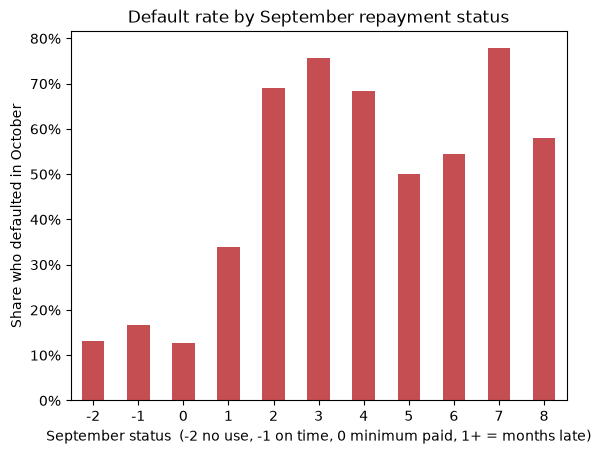

In [6]:
rate = df.groupby("pay_status_sep")["default"].mean()
ax = rate.plot.bar(color="#C44E52", rot=0)
ax.set_title("Default rate by September repayment status")
ax.set_xlabel("September status  (-2 no use, -1 on time, 0 minimum paid, 1+ = months late)")
ax.set_ylabel("Share who defaulted in October")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
plt.show()

This is the clearest pattern in the data. Customers who paid on time, or paid the minimum, defaulted
only about **13–17%** of the time. Customers who were already **2 months late** defaulted about **69%** of the
time. (The bars for 5+ months late are based on very few customers, so they jump around.)
Recent repayment behaviour will probably be the model's strongest signal.

## Summary
- 30,000 customers, 23 input columns, no missing values.
- 22% default rate, so the data is imbalanced.
- Some undocumented category codes need cleaning.
- Recent late payments look strongly linked to default.

**Next (Milestone 2):** explore the data properly to see which customer types are riskiest.